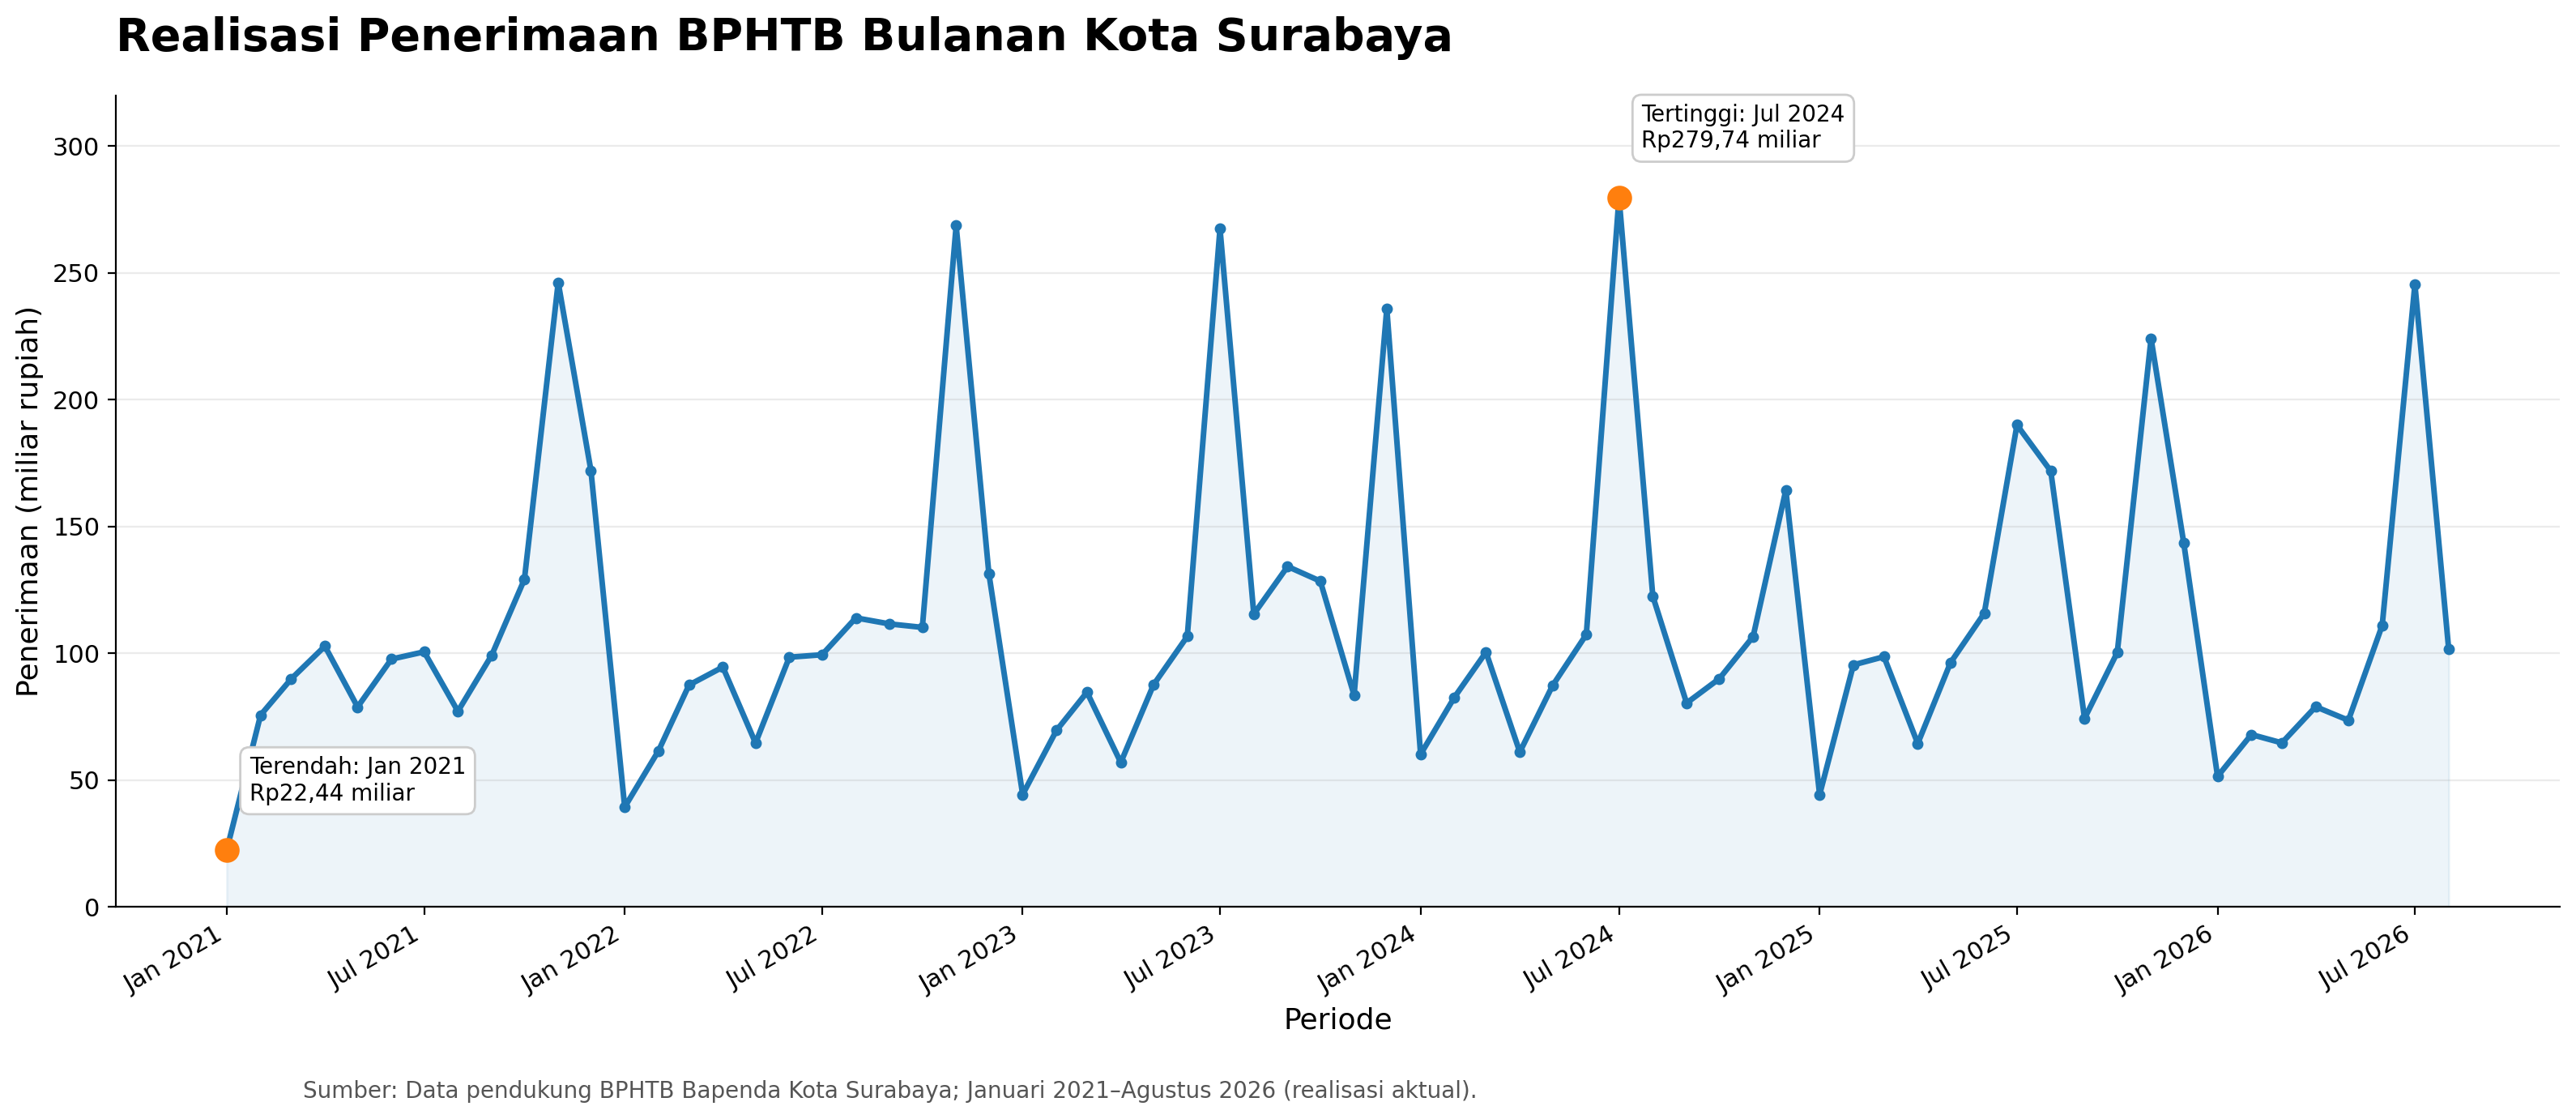

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

file_path = "Data Pendukung BPHTB PAK 2026 dan Target 2027.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="uraian",
    header=None
)

# Posisi kolom realisasi pada file Excel
kolom_realisasi = {
    2021: 4,
    2022: 8,
    2023: 12,
    2024: 16,
    2025: 24,
    2026: 32
}


data = []

for tahun, kolom in kolom_realisasi.items():

    # Tahun 2026 hanya menggunakan realisasi Jan–Agu
    jumlah_bulan = 8 if tahun == 2026 else 12

    for bulan in range(1, jumlah_bulan + 1):

        # Baris Januari dimulai dari indeks 5
        nilai = df.iloc[bulan + 4, kolom]

        if pd.notna(nilai):
            data.append({
                "Periode": pd.Timestamp(tahun, bulan, 1),
                "Realisasi": float(nilai) / 1e9
            })

bphtb = pd.DataFrame(data)
bphtb = bphtb.sort_values("Periode")

idx_min = bphtb["Realisasi"].idxmin()
idx_max = bphtb["Realisasi"].idxmax()

data_min = bphtb.loc[idx_min]
data_max = bphtb.loc[idx_max]

fig, ax = plt.subplots(figsize=(16, 7), dpi=200)

# Grafik utama
ax.plot(
    bphtb["Periode"],
    bphtb["Realisasi"],
    color="#1f77b4",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Realisasi BPHTB"
)

# Area transparan di bawah garis
ax.fill_between(
    bphtb["Periode"],
    bphtb["Realisasi"],
    0,
    color="#1f77b4",
    alpha=0.08
)

# Penanda nilai minimum dan maksimum
ax.scatter(
    [data_min["Periode"], data_max["Periode"]],
    [data_min["Realisasi"], data_max["Realisasi"]],
    color="#ff7f0e",
    s=100,
    zorder=5
)

# Anotasi nilai terendah
ax.annotate(
    f"Terendah: {data_min['Periode']:%b %Y}\n"
    f"Rp{data_min['Realisasi']:.2f} miliar".replace(".", ","),
    xy=(data_min["Periode"], data_min["Realisasi"]),
    xytext=(10, 22),
    textcoords="offset points",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.4",
        fc="white",
        ec="#cccccc"
    )
)

# Anotasi nilai tertinggi
ax.annotate(
    f"Tertinggi: {data_max['Periode']:%b %Y}\n"
    f"Rp{data_max['Realisasi']:.2f} miliar".replace(".", ","),
    xy=(data_max["Periode"], data_max["Realisasi"]),
    xytext=(10, 22),
    textcoords="offset points",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.4",
        fc="white",
        ec="#cccccc"
    )
)

ax.set_title(
    "Realisasi Penerimaan BPHTB Bulanan Kota Surabaya",
    fontsize=20,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xlabel("Periode", fontsize=13)
ax.set_ylabel("Penerimaan (miliar rupiah)", fontsize=13)

# Label sumbu X setiap Januari dan Juli
ax.xaxis.set_major_locator(
    mdates.MonthLocator(bymonth=[1, 7])
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=30, ha="right")

ax.set_ylim(0, 320)

# Garis bantu
ax.grid(
    axis="y",
    linestyle="-",
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", labelsize=11)

# Sumber data
fig.text(
    0.12, 0.025,
    "Sumber: Data pendukung BPHTB Bapenda Kota Surabaya; "
    "Januari 2021–Agustus 2026 (realisasi aktual).",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.savefig(
    "Grafik_Realisasi_BPHTB_Bulanan.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()